# Creditworthiness modelling: XGB Classification

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import optuna
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, RobustScaler
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from xgboost import XGBClassifier
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, roc_auc_score, f1_score, 
                            classification_report, confusion_matrix, 
                            ConfusionMatrixDisplay)

## <font color="orange"> Data loading <font>

In [28]:
# load data
path = "../data/processed-data/processed_data.csv"
df = pd.read_csv(path)

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32574 entries, 0 to 32573
Data columns (total 22 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   person_age_years                  32574 non-null  int64  
 1   person_home_ownership             32574 non-null  str    
 2   person_emp_length_years           31679 non-null  float64
 3   loan_intent                       32574 non-null  str    
 4   loan_grade                        32574 non-null  str    
 5   loan_int_rate                     29459 non-null  float64
 6   loan_status                       32574 non-null  int64  
 7   cb_person_default_on_file         32574 non-null  int64  
 8   cb_person_cred_hist_length_years  32574 non-null  int64  
 9   loan_term_months                  32574 non-null  int64  
 10  loan_to_income_ratio              32574 non-null  float64
 11  open_accounts                     32574 non-null  int64  
 12  credit_utilizat


## <font color="orange"> Preparation <font>

In [30]:
# X/y split
y = df.pop("loan_status")
X = df.copy()

In [31]:
# train-test stratified split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

## <font color="orange"> XGB Classifier <font>

In [32]:
# feature division 
binary_features = ["high_lti", "loan_grade_sep", "high_income", "high_lti_x_rent", "cb_person_default_on_file"]
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
numeric_features = [ft for ft in numeric_features if ft not in binary_features]
ohe_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

In [33]:
# optuna study + cross validation without kNN imputer
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
def optuna_study(metric: str, ntrials: int=100): 
    def objective(trial):
        """ Objective function """
        # hyperparams for xgbClassifier
        ib_ratio = (y_train==0).sum() / (y_train==1).sum()
        xgb_scale_pos_weight = trial.suggest_float("xgb_scale_pos_weight", 1.0, 2 * ib_ratio)
        xgb_n_estimators = trial.suggest_int("xgb_n_estimators", 80, 1000, step=20)
        xgb_eta= trial.suggest_float("xgb_eta", 1e-2, 1.0, log=True)
        xgb_min_child_weight= trial.suggest_float("xgb_min_child_weight", 1.0, 10.0)
        xgb_max_depth = trial.suggest_int("xgb_max_depth", 3, 10)
        xgb_subsample = trial.suggest_float("xgb_subsample", 0.55, 1.0)
        xgb_colsample_bytree = trial.suggest_float("xgb_colsample_bytree", 0.5, 1.0)       
        xgb_gamma = trial.suggest_float("xgb_gamma", 0, 6)
        xgb_alpha = trial.suggest_float("xgb_alpha", 0, 1)
    
        # processor pipeline
        preprocessor = ColumnTransformer(
            transformers=[
                ("ohe", Pipeline([
                    ("encoder", OneHotEncoder(handle_unknown="ignore")),
                ]), ohe_features),
            ],
            remainder="passthrough",
        )
        # Logistic regression pipeline
        xgb_pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", XGBClassifier(
                n_estimators = xgb_n_estimators,
                eta = xgb_eta,
                max_depth = xgb_max_depth,
                min_child_weight = xgb_min_child_weight,
                subsample = xgb_subsample,
                colsample_bytree = xgb_colsample_bytree,
                scale_pos_weight = xgb_scale_pos_weight,
                gamma = xgb_gamma,
                alpha = xgb_alpha,
                random_state = 42, 
            )),
        ])

        if metric=="f1":
            # tuned threshold instead of using default 0.5
            threshold = trial.suggest_float("threshold", 0.15, 0.75)
            def f1_at_threshold(estimator, X, y):
                proba = estimator.predict_proba(X)[:, 1]
                return f1_score(y, (proba >= threshold).astype(int))
        
            scores = cross_val_score(xgb_pipeline, X_train, y_train, scoring=f1_at_threshold, cv=cv, n_jobs=-1)
        else:
            scores = cross_val_score(xgb_pipeline, X_train, y_train, scoring=metric, cv=cv, n_jobs=-1)
        return scores.mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=ntrials)

    return study

In [34]:
def retrain_and_evaluation(study, metric):
    best_params = study.best_params

    preprocessor = ColumnTransformer(
        transformers=[
            ("ohe", Pipeline([
                ("encoder", OneHotEncoder(handle_unknown="ignore")),
            ]), ohe_features),
        ],
        remainder="passthrough",
    )

    best_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
                    n_estimators = best_params["xgb_n_estimators"],
                    eta = best_params["xgb_eta"],
                    max_depth = best_params["xgb_max_depth"],
                    min_child_weight = best_params["xgb_min_child_weight"],
                    subsample = best_params["xgb_subsample"],
                    colsample_bytree = best_params["xgb_colsample_bytree"],
                    scale_pos_weight = best_params["xgb_scale_pos_weight"],
                    gamma = best_params["xgb_gamma"],
                    alpha = best_params["xgb_alpha"],
                    random_state = 42,  
        )),
    ])

    best_pipeline.fit(X_train, y_train)
    y_prob = best_pipeline.predict_proba(X_test)[:, 1]
    threshold = best_params.get("threshold", 0.5)
    y_pred = (y_prob >= threshold).astype(int)

    print(f"Best CV {metric.upper()}:             {study.best_value:.4f}")
    print(f"Test F1:                {f1_score(y_test, y_pred):.4f}")
    print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
    print(f"Test ROC-AUC:           {roc_auc_score(y_test, y_prob):.4f}")
    print(f"Test average precision: {average_precision_score(y_test, y_prob):.4f}")
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, zero_division=0, digits=3))

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
    plt.show()

    # Training-set metrics for the best-performing pipeline
    y_train_prob = best_pipeline.predict_proba(X_train)[:, 1]
    y_train_pred = (y_train_prob >= threshold).astype(int)   # tuned threshold

    print(f"Training F1:                {f1_score(y_train, y_train_pred):.4f}")
    print(f"Training balanced accuracy: {balanced_accuracy_score(y_train, y_train_pred):.4f}")
    print(f"Training ROC-AUC:           {roc_auc_score(y_train, y_train_prob):.4f}")
    print(f"Training average precision: {average_precision_score(y_train, y_train_prob):.4f}")

    print("\nTraining classification report:")
    print(classification_report(y_train, y_train_pred, zero_division=0, digits=3))

    ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred)
    plt.show()

    return best_pipeline

In [35]:
# study to optimize f1 score: without knn
f1_study = optuna_study(metric="f1")

print("Best performing pipeline: ")
print(f1_study.best_trial)

print("Best params:")
print(f1_study.best_value, f1_study.best_params)

[I 2026-11-18 21:44:20,487] A new study created in memory with name: no-name-7b1e06c2-97cd-4939-b1f5-aef886f790e9


[I 2026-11-18 21:44:25,139] Trial 0 finished with value: 0.8127631005533233 and parameters: {'xgb_scale_pos_weight': 3.309422540764778, 'xgb_n_estimators': 960, 'xgb_eta': 0.29106359131330695, 'xgb_min_child_weight': 6.387926357773329, 'xgb_max_depth': 4, 'xgb_subsample': 0.6201975341512912, 'xgb_colsample_bytree': 0.5290418060840998, 'xgb_gamma': 5.197056874649611, 'xgb_alpha': 0.6011150117432088, 'threshold': 0.5748435466776273}. Best is trial 0 with value: 0.8127631005533233.
[I 2026-11-18 21:44:29,853] Trial 1 finished with value: 0.8062505705799667 and parameters: {'xgb_scale_pos_weight': 1.1269244407335268, 'xgb_n_estimators': 980, 'xgb_eta': 0.46225890010208287, 'xgb_min_child_weight': 2.9110519961044856, 'xgb_max_depth': 4, 'xgb_subsample': 0.6325320294340453, 'xgb_colsample_bytree': 0.6521211214797689, 'xgb_gamma': 3.148538589793427, 'xgb_alpha': 0.43194501864211576, 'threshold': 0.32473748411882514}. Best is trial 0 with value: 0.8127631005533233.
[I 2026-11-18 21:44:31,590] 

Best performing pipeline: 
FrozenTrial(number=67, state=<TrialState.COMPLETE: 1>, values=[0.844726296095833], datetime_start=datetime.datetime(2026, 11, 18, 23, 47, 45, 32245), datetime_complete=datetime.datetime(2026, 11, 18, 23, 47, 47, 830971), params={'xgb_scale_pos_weight': 2.8742073295961235, 'xgb_n_estimators': 240, 'xgb_eta': 0.12223912916840698, 'xgb_min_child_weight': 2.786623930789354, 'xgb_max_depth': 8, 'xgb_subsample': 0.98505681575135, 'xgb_colsample_bytree': 0.9692339781692259, 'xgb_gamma': 1.9897003939123143, 'xgb_alpha': 0.22351308783022633, 'threshold': 0.664974725372188}, user_attrs={}, system_attrs={'tpe:relative_params:0': '{"threshold": 0.664974725372188, "xgb_alpha": 0.22351308783022633, "xgb_colsample_bytree": 0.9692339781692259, "xgb_eta": 0.12223912916840698, "xgb_gamma": 1.9897003939123143, "xgb_max_depth": 8, "xgb_min_child_weight": 2.786623930789354, "xgb_n_estimators": 240, "xgb_scale_pos_weight": 2.8742073295961235, "xgb_subsample": 0.98505681575135}'}, 

Best CV F1:             0.8447
Test F1:                0.8329
Test balanced accuracy: 0.8617
Test ROC-AUC:           0.9465
Test average precision: 0.9029

Classification report:
              precision    recall  f1-score   support

           0      0.929     0.994     0.961      5094
           1      0.970     0.730     0.833      1421

    accuracy                          0.936      6515
   macro avg      0.950     0.862     0.897      6515
weighted avg      0.938     0.936     0.933      6515



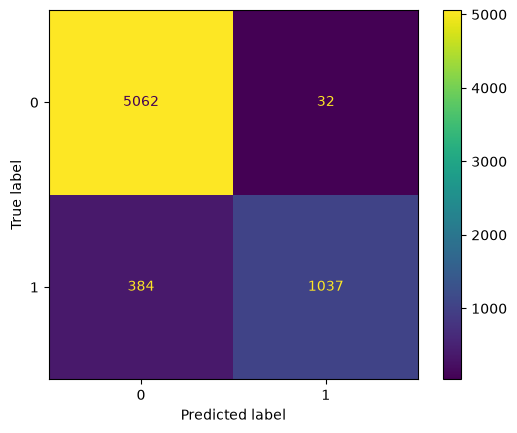

Training F1:                0.8959
Training balanced accuracy: 0.9073
Training ROC-AUC:           0.9943
Training average precision: 0.9843

Training classification report:
              precision    recall  f1-score   support

           0      0.951     0.998     0.974     20373
           1      0.993     0.816     0.896      5686

    accuracy                          0.959     26059
   macro avg      0.972     0.907     0.935     26059
weighted avg      0.960     0.959     0.957     26059



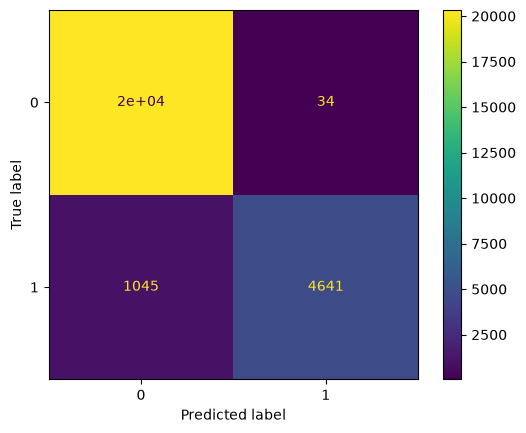

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['person_age_years','person_home_ownership','person_emp_length_years',..., 'high_lti_x_rent','log_person_income_usd','log_loan_amount_usd']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ohe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of 

In [36]:
# evaluation
best_f1_pipeline = retrain_and_evaluation(f1_study, metric="f1")
best_f1_pipeline

## <font color="orange">SHAP feature importance <font>

In [ ]:
# Explain a manageable sample of the held-out data
background_raw = X_train # reference population
explain_raw = X_test # population to explain

# Extract necessary info from the best pipeline
preprocessor = best_f1_pipeline.named_steps["preprocessor"]
best_clf = best_f1_pipeline.named_steps["classifier"]
feature_names = preprocessor.get_feature_names_out()

# preprocessing transform to get what enter the classifier
background = preprocessor.transform(background_raw)
explain_data = preprocessor.transform(explain_raw)

# Convert sparse matrices to dense if necessary
if hasattr(background, "toarray"):
    background = background.toarray()
if hasattr(explain_data, "toarray"):
    explain_data = explain_data.toarray()
# wrap to dataframes
background = pd.DataFrame(background, columns=feature_names, index=background_raw.index)
explain_data = pd.DataFrame(explain_data, columns=feature_names, index=explain_raw.index)

# calculate SHAP values. LinearExplainer for Logit
masker = shap.maskers.Independent(background, max_samples=len(background))
explainer = shap.TreeExplainer(best_clf, masker)
shap_values = explainer(explain_data)

# Map each encoded column back to its original feature
def to_original(fname, raw_cols): # raw_cols: original cols
    stripped = fname.split("__", 1)[-1]  # drop transformer prefix
    # a col belongs to an original feature c if name=c (like numetics) or starts with c_ (OHE) 
    matches = [c for c in raw_cols if stripped == c or stripped.startswith(c + "_")]
    return max(matches, key=len) if matches else stripped  # longest match avoids prefix clashes

groups = np.array([to_original(f, X_train.columns) for f in feature_names])

# Sum SHAP values within each original feature per sample, then take the mean absolute value.
# SHAP is additive, so summing signed values per sample is the correct way to aggregate.
agg_df = (
    pd.DataFrame(shap_values.values, columns=feature_names)
    .T.groupby(groups).sum().T
)
agg_exp = shap.Explanation(
    values=agg_df.values,
    base_values=shap_values.base_values,
    feature_names=list(agg_df.columns),
)

# Importance per ORIGINAL feature (one-hot levels combined)
shap.plots.bar(agg_exp, max_display=15, show=False)
plt.xlabel("Mean |SHAP value| (log-odds)")
plt.tight_layout()
plt.show()

# Direction of impact per ENCODED feature (colors need the encoded values)
shap.plots.beeswarm(shap_values, max_display=20, show=False)
plt.xlabel("SHAP value (impact on log-odds of the predicted class)")
plt.tight_layout()
plt.show()


  8%|==                  | 543/6515 [08:52<97:31]        